# 09 — Optional Classification: Confusion Matrix
## Why is this separate?

Our main task is **regression**: predict an exact-ish number of minutes.

A confusion matrix is for **classification**. If the business later wants a binary decision such as:

- `On Time` = delivery time <= 30 minutes
- `Delayed` = delivery time > 30 minutes

then we can create a separate classification target from historical delivery time.

This does NOT replace the regression model.

              precision    recall  f1-score   support

     On Time       0.90      0.94      0.92      6397
     Delayed       0.84      0.76      0.79      2720

    accuracy                           0.88      9117
   macro avg       0.87      0.85      0.86      9117
weighted avg       0.88      0.88      0.88      9117



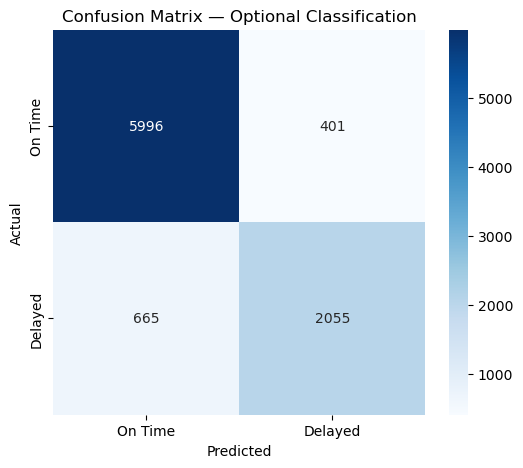

,Accuracy,Precision,Recall,F1
0,0.883,0.837,0.756,0.794


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score
)

df = pd.read_csv("../outputs/cleaned/zomato_model_dataset.csv")

# Historical label only: this is the outcome we want to predict.
df["Delayed"] = (df["Time_taken (min)"] > 30).astype(int)

target = "Delayed"
X = df.drop(columns=[target, "Time_taken (min)"])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

num = X.select_dtypes(include=["number"]).columns.tolist()
cat = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

clf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print(classification_report(y_test, pred, target_names=["On Time", "Delayed"]))

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["On Time", "Delayed"],
    yticklabels=["On Time", "Delayed"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Optional Classification")
plt.show()

pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred)
}]).round(3)

## Important distinction

Regression asks:

> "How many minutes will delivery take?"

Classification asks:

> "Will this order be delayed?"

Both can be useful, but they answer different business questions.